# 03 - Cleaning: remove interference spikes and per-frame noise

`dsp.clean_window` = `despike` (median of 5 frames, removes 1-2 frame bursts) then `smooth` (average of 5 frames, removes random fuzz).
Human motion is slow compared with 5 ms per frame, so it should survive.

Checks:
1. Pictures before / after for the worst cases.
2. Spike share and noise level before / after, for every room. Goal: labelled rooms look more like the unlabelled ones.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data, dsp

lab = data.load_index("labeled"); lab["set"] = "L"
unl = data.load_index("unlabeled"); unl["set"] = "U"; unl["headcount"] = -1
idx = pd.concat([lab, unl], ignore_index=True)

## 1. Before / after pictures (|complex dynamic part|, Rx0)

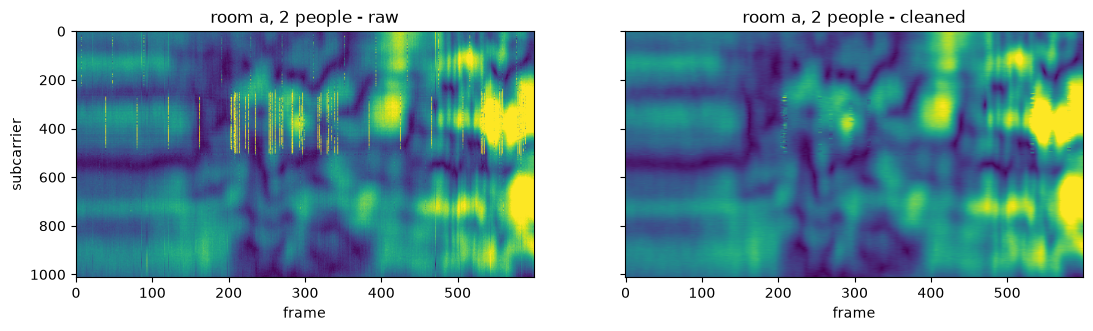

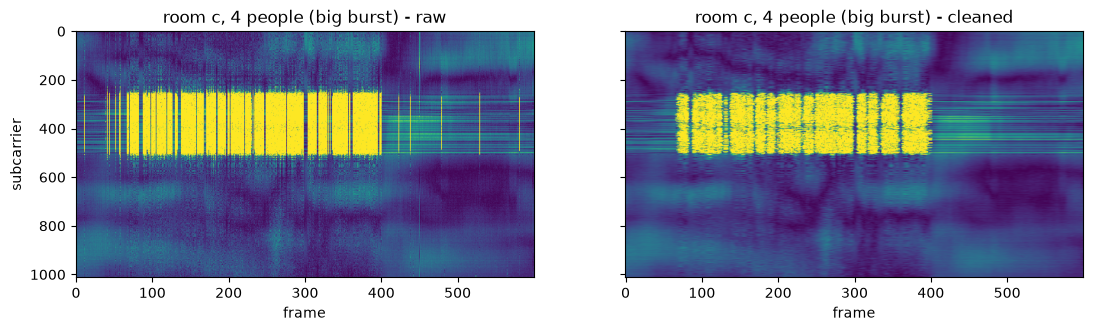

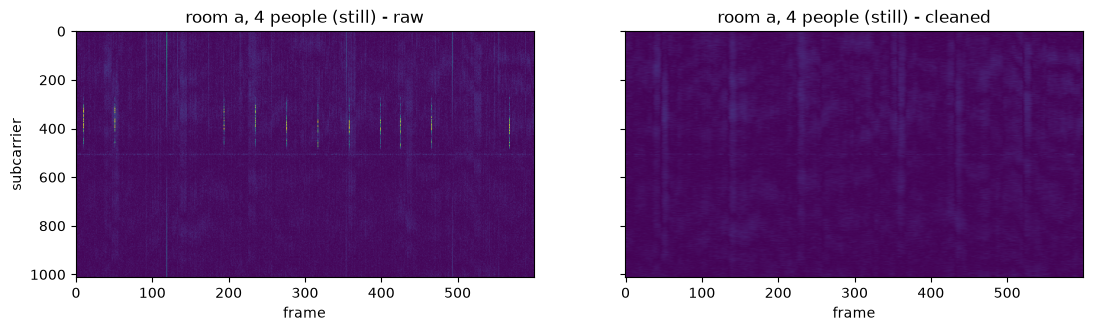

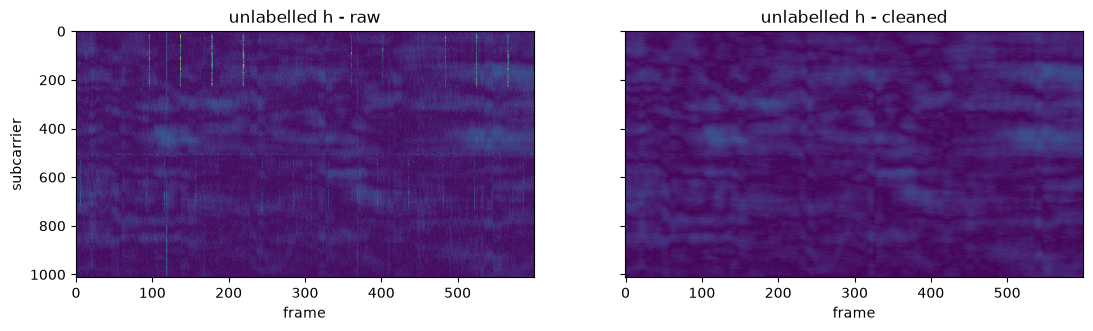

In [2]:
def before_after(identifier, which, start=0, title=""):
    csi, _ = data.load_trace(identifier, which)
    w = dsp.normalize_gain(csi[start:start + 600])
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
    for ax, x, name in [(axes[0], w, "raw"), (axes[1], dsp.clean_window(w), "cleaned")]:
        _, dyn = dsp.split_static_dynamic(dsp.clean(x))
        ax.imshow(np.abs(dyn[:, 0]).T, aspect="auto", cmap="viridis", vmin=0, vmax=0.05)
        ax.set_title(f"{title} - {name}"); ax.set_xlabel("frame")
    axes[0].set_ylabel("subcarrier"); plt.show()

before_after("a_a1_hash058655_2", "labeled", title="room a, 2 people")
before_after("c_c1_hash292683_4", "labeled", title="room c, 4 people (big burst)")
before_after("a_a1_hash844151_4", "labeled", title="room a, 4 people (still)")
before_after(unl.identifier.iloc[0], "unlabeled", title=f"unlabelled {unl.layout.iloc[0]}")

## 2. Doppler spectrum before / after (room g, empty vs 1 person)
The empty-room recordings of g had a high flat floor (= random noise). After cleaning, the floor should drop.

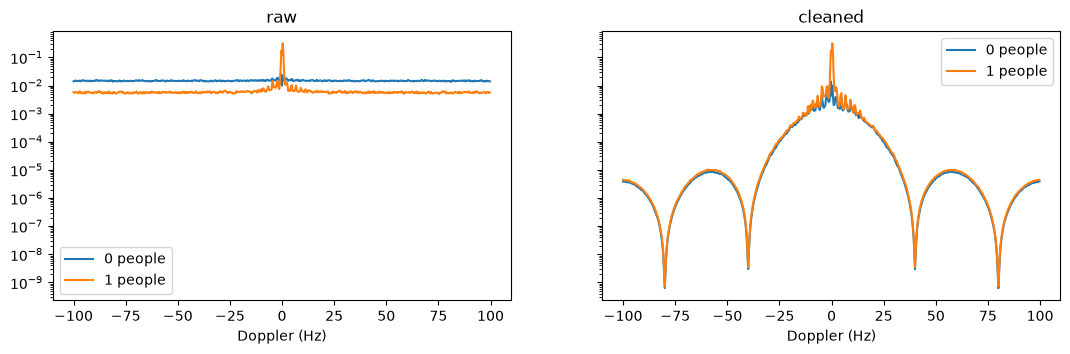

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, cleaned in zip(axes, [False, True]):
    for hc in [0, 1]:
        specs = []
        for tid in lab[(lab.layout == "g") & (lab.headcount == hc)].identifier:
            csi, _ = data.load_trace(tid)
            w = dsp.normalize_gain(csi[:600])
            if cleaned: w = dsp.clean_window(w)
            f, p = dsp.doppler_spectrum(dsp.clean(w)); specs.append(p)
        ax.semilogy(f, np.mean(specs, 0), label=f"{hc} people")
    ax.set_title("cleaned" if cleaned else "raw"); ax.set_xlabel("Doppler (Hz)"); ax.legend()
plt.show()

## 3. All rooms: spike share and noise level, before vs after
- `spikes`: share of frames with a burst (max over the 4 sub-bands)
- `noise`: share of Doppler power above 40 Hz (people rarely move that fast -> mostly noise)

One window per trace (frames 3000-3600).

In [4]:
def noise_share(w):
    f, p = dsp.doppler_spectrum(dsp.clean(w))
    return p[np.abs(f) > 40].sum() / p.sum()

rows = []
for _, r in idx.iterrows():
    csi, _ = data.load_trace(r.identifier, "labeled" if r.set == "L" else "unlabeled")
    w = dsp.normalize_gain(csi[3000:3600])
    c = dsp.clean_window(w)
    rows.append({"set": r.set, "layout": r.layout, "headcount": r.headcount,
                 "spikes_raw": dsp.spike_fraction(w).max(), "spikes_clean": dsp.spike_fraction(c).max(),
                 "noise_raw": noise_share(w), "noise_clean": noise_share(c)})
q = pd.DataFrame(rows)
q.to_csv("../cache/cleaning_check.csv", index=False)
q.assign(room=q.set + ":" + q.layout).groupby("room")[["spikes_raw", "spikes_clean", "noise_raw", "noise_clean"]].median().round(3)

,spikes_raw,spikes_clean,noise_raw,noise_clean
room,,,,
L:a,0.037,0.0,0.253,0.001
L:b,0.047,0.0,0.544,0.006
L:c,0.038,0.0,0.239,0.000
L:e,0.003,0.0,0.031,0.000
L:g,0.042,0.0,0.572,0.005
L:unknown,0.058,0.0,0.165,0.000
U:d,0.008,0.0,0.550,0.007
U:h,0.004,0.0,0.361,0.002
U:i,0.003,0.0,0.129,0.000


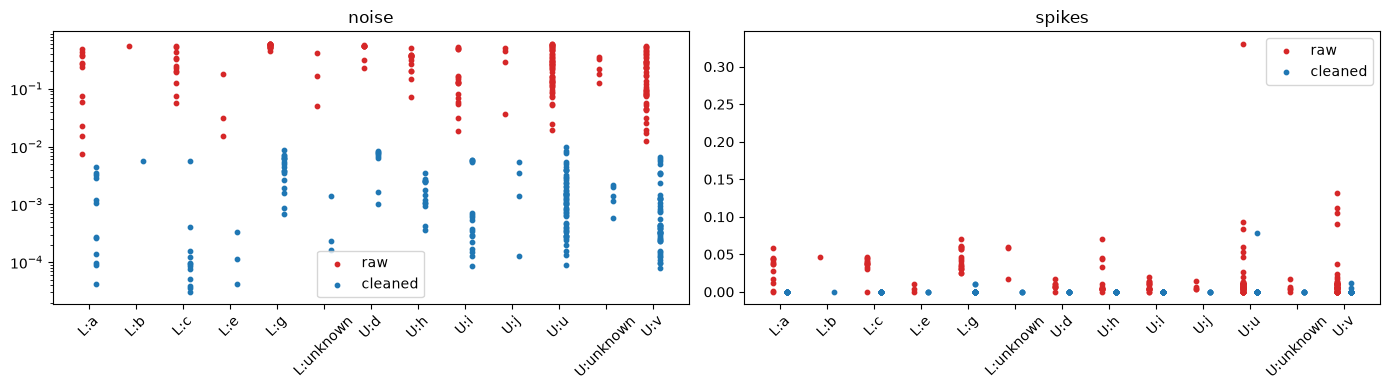

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
q["room"] = q.set + ":" + q.layout
rooms = sorted(q.room.unique())
for ax, col in zip(axes, ["noise", "spikes"]):
    for x, rm in enumerate(rooms):
        d = q[q.room == rm]
        ax.scatter(np.full(len(d), x - 0.15), d[f"{col}_raw"], s=10, c="tab:red", label="raw" if x == 0 else None)
        ax.scatter(np.full(len(d), x + 0.15), d[f"{col}_clean"], s=10, c="tab:blue", label="cleaned" if x == 0 else None)
    ax.set_xticks(range(len(rooms))); ax.set_xticklabels(rooms, rotation=45); ax.set_title(col); ax.legend()
axes[0].set_yscale("log")
plt.tight_layout(); plt.show()


## Findings (2026-10-24)

1. **Short spikes are removed** (room a, 2 people): the thin vertical lines are gone, the slow blobs from people are kept.
2. **Long bursts are NOT removed** (room c, 4 people, frames 70-400): the burst covers most frames for ~1.5 s, so the median of 5 frames is still a burst frame. A median filter can only fix bursts shorter than half its width. A fix would be to detect a corrupted 20 MHz sub-band and ignore it -> later.
3. **The noise-level shortcut in room g is gone:** raw, the empty room had a ~3x higher flat floor than 1 person; cleaned, the two curves overlap. The bad news: below ~20 Hz they also look almost identical, so 0 vs 1 person in room g is genuinely hard.
4. The 5-frame average is a low-pass filter: it keeps motion below ~20 Hz Doppler and cuts above (zeros at 40, 80 Hz). Slow motion and breathing survive; very fast walking (> ~0.6 m/s) is weakened. The "noise" and "spikes" numbers in the table drop to ~0 partly *by construction*, so they confirm the filter runs, not that it is perfect.
